DOWNLOADING DIABETIC RETINOPATHY DATASET


100%|██████████| 1.94G/1.94G [01:37<00:00, 21.3MB/s]

Extracting files...



Dataset downloaded successfully!
Dataset location: /content/kaggle_data

Detected Dataset Directory: /content/kaggle_data/colored_images/colored_images

Detected Classes:
- Mild
- Moderate
- No_DR
- Proliferate_DR
- Severe

DATASET DISTRIBUTION


,Class,Number of Images
0,Mild,2443
1,Moderate,5292
2,No_DR,25810
3,Proliferate_DR,708
4,Severe,873


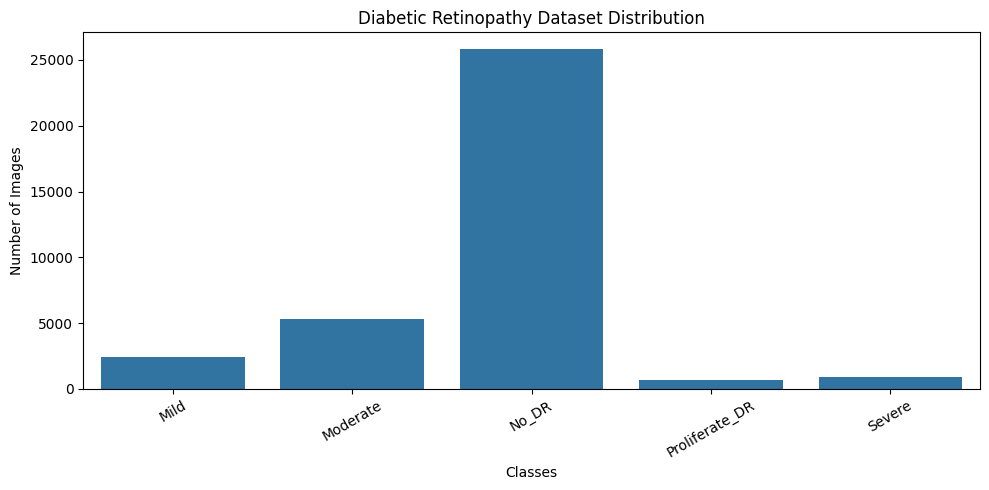


STARTING IMAGE FEATURE EXTRACTION

Processing Mild: 1000 images


Mild:   0%|          | 0/1000 [00:00<?, ?it/s]


Processing Moderate: 1000 images


Moderate:   0%|          | 0/1000 [00:00<?, ?it/s]


Processing No_DR: 1000 images


No_DR:   0%|          | 0/1000 [00:00<?, ?it/s]


Processing Proliferate_DR: 708 images


Proliferate_DR:   0%|          | 0/708 [00:00<?, ?it/s]


Processing Severe: 873 images


Severe:   0%|          | 0/873 [00:00<?, ?it/s]


FEATURE EXTRACTION COMPLETED
Feature Matrix Shape: (4581, 8206)
Target Array Shape: (4581,)

Class Distribution After Processing:
Mild              1000
Moderate          1000
No_DR             1000
Severe             873
Proliferate_DR     708
Name: count, dtype: int64

DATASET SPLITTING COMPLETED
Training Samples: 3206
Validation Samples: 687
Testing Samples: 688

Training Percentage: 69.98 %
Validation Percentage: 15.0 %
Testing Percentage: 15.02 %

STARTING SVM HYPERPARAMETER OPTIMIZATION
Fitting 3 folds for each of 9 candidates, totalling 27 fits

BEST HYPERPARAMETERS:
{'svm__C': 10, 'svm__gamma': 'scale'}

BEST CROSS-VALIDATION ACCURACY:
0.3060

TRAINING PERFORMANCE
Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1 Score  : 1.0000

CLASSIFICATION REPORT
                precision    recall  f1-score   support

          Mild       1.00      1.00      1.00       700
      Moderate       1.00      1.00      1.00       700
         No_DR       1.00      1.00      1.00     

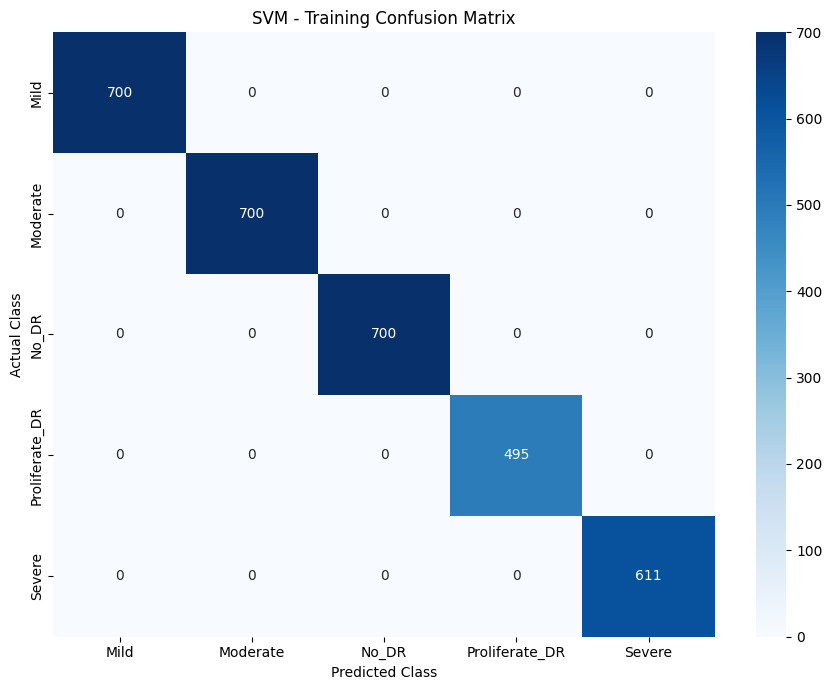


VALIDATION PERFORMANCE
Accuracy  : 0.3130
Precision : 0.3184
Recall    : 0.3130
F1 Score  : 0.3122

CLASSIFICATION REPORT
                precision    recall  f1-score   support

          Mild       0.31      0.41      0.35       150
      Moderate       0.27      0.26      0.26       150
         No_DR       0.27      0.29      0.28       150
Proliferate_DR       0.41      0.35      0.38       106
        Severe       0.36      0.26      0.30       131

      accuracy                           0.31       687
     macro avg       0.32      0.31      0.32       687
  weighted avg       0.32      0.31      0.31       687



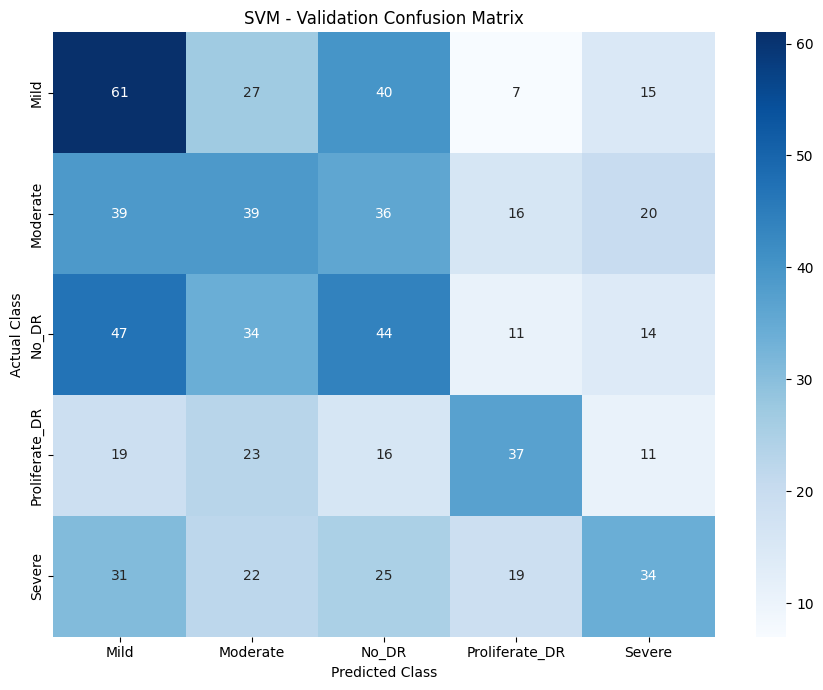


TESTING PERFORMANCE
Accuracy  : 0.2776
Precision : 0.2800
Recall    : 0.2776
F1 Score  : 0.2771

CLASSIFICATION REPORT
                precision    recall  f1-score   support

          Mild       0.28      0.33      0.30       150
      Moderate       0.18      0.17      0.17       150
         No_DR       0.27      0.31      0.29       150
Proliferate_DR       0.37      0.32      0.34       107
        Severe       0.33      0.27      0.30       131

      accuracy                           0.28       688
     macro avg       0.29      0.28      0.28       688
  weighted avg       0.28      0.28      0.28       688



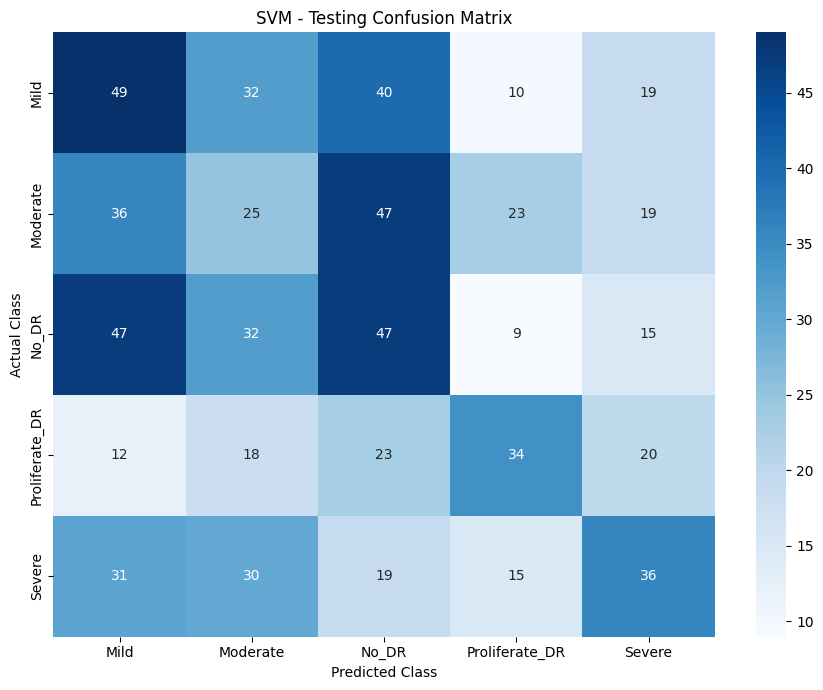


FINAL SVM PERFORMANCE SUMMARY


,Dataset,Accuracy,Precision,Recall,F1 Score
0,Training,1.0000,1.0000,1.0000,1.0000
1,Validation,0.3130,0.3184,0.3130,0.3122
2,Testing,0.2776,0.2800,0.2776,0.2771


<Figure size 1100x600 with 0 Axes>

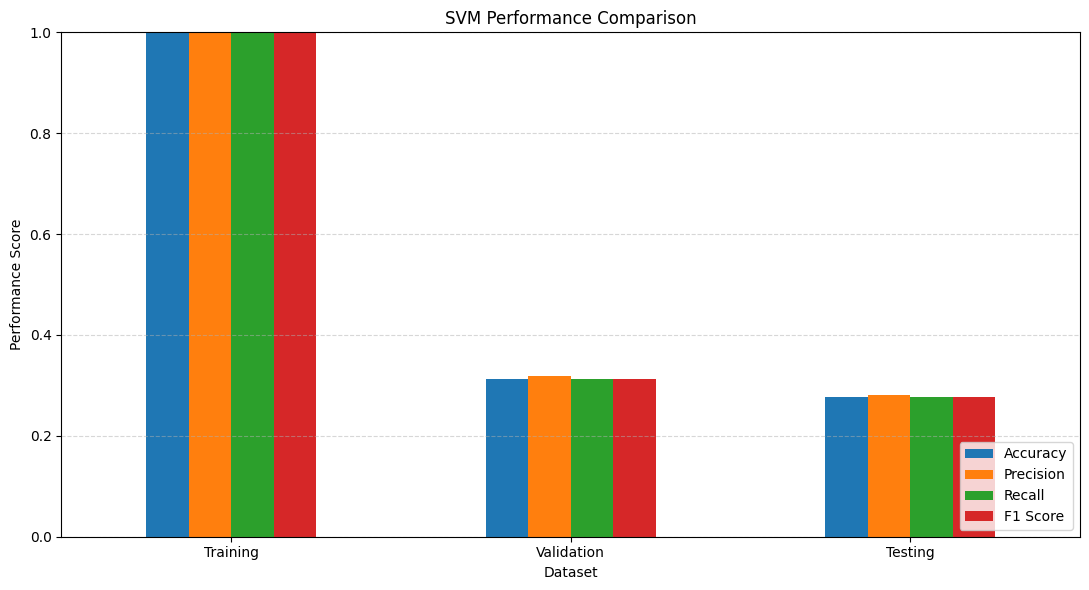


SVM EXPERIMENT COMPLETED SUCCESSFULLY

SAVED OUTPUT FILES:
/content/SVM_Output/best_parameters.csv
/content/SVM_Output/classes.pkl
/content/SVM_Output/classification_report.csv
/content/SVM_Output/results.csv
/content/SVM_Output/svm_model.pkl

Output ZIP Created: /content/SVM_Output.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ================================================================
# DIABETIC RETINOPATHY CLASSIFICATION USING SUPPORT VECTOR MACHINE
# DATASET: KAGGLE - DIABETIC RETINOPATHY 2015
# PLATFORM: GOOGLE COLAB
# ================================================================


# ================================================================
# 1. INSTALL REQUIRED LIBRARIES
# ================================================================

!pip -q install -U kagglehub scikit-image opencv-python-headless


# ================================================================
# 2. IMPORT LIBRARIES
# ================================================================

import os
import cv2
import joblib
import shutil
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from tqdm.auto import tqdm
from skimage.feature import hog, local_binary_pattern

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from google.colab import files


# ================================================================
# 3. CONFIGURATION
# ================================================================

DATASET_ID = "sovitrath/diabetic-retinopathy-2015-data-colored-resized"

IMG_SIZE = 128
RANDOM_STATE = 42

MAX_IMAGES_PER_CLASS = 1000

OUTPUT_DIR = "/content/SVM_Output"

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"
}

np.random.seed(RANDOM_STATE)


# ================================================================
# 4. DOWNLOAD DATASET DIRECTLY FROM KAGGLE
# ================================================================

print("=" * 65)
print("DOWNLOADING DIABETIC RETINOPATHY DATASET")
print("=" * 65)

DATA_DIR = kagglehub.dataset_download(
    DATASET_ID,
    output_dir="/content/kaggle_data"
)

print("\nDataset downloaded successfully!")
print("Dataset location:", DATA_DIR)


# ================================================================
# 5. AUTOMATIC DATASET DIRECTORY DETECTION
# ================================================================

DATA_DIR = str(DATA_DIR)

class_root = None

for root, dirs, folder_files in os.walk(DATA_DIR):

    if "No_DR" in dirs:
        class_root = root
        break

if class_root is None:

    raise FileNotFoundError(
        "No_DR folder not found. Please verify the Kaggle dataset structure."
    )

DATA_DIR = class_root

class_names = sorted([
    folder
    for folder in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, folder))
])

if len(class_names) < 2:
    raise ValueError("At least two class folders are required.")

print("\nDetected Dataset Directory:", DATA_DIR)

print("\nDetected Classes:")

for class_name in class_names:
    print("-", class_name)


# ================================================================
# 6. DISPLAY DATASET DISTRIBUTION
# ================================================================

class_distribution = {}

for class_name in class_names:

    folder = os.path.join(DATA_DIR, class_name)

    image_count = sum(
        1 for filename in os.listdir(folder)
        if Path(filename).suffix.lower() in IMAGE_EXTENSIONS
    )

    class_distribution[class_name] = image_count

distribution_df = pd.DataFrame(
    list(class_distribution.items()),
    columns=["Class", "Number of Images"]
)

print("\nDATASET DISTRIBUTION")

display(distribution_df)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=distribution_df,
    x="Class",
    y="Number of Images"
)

plt.title("Diabetic Retinopathy Dataset Distribution")
plt.xlabel("Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# ================================================================
# 7. IMAGE FEATURE EXTRACTION
# HOG + COLOR HISTOGRAM + LOCAL BINARY PATTERN
# ================================================================

X = []
y = []

print("\n" + "=" * 65)
print("STARTING IMAGE FEATURE EXTRACTION")
print("=" * 65)

rng = np.random.default_rng(RANDOM_STATE)

for class_name in class_names:

    folder = os.path.join(DATA_DIR, class_name)

    image_files = [
        filename
        for filename in os.listdir(folder)
        if Path(filename).suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_files.sort()

    if MAX_IMAGES_PER_CLASS is not None:

        selected_count = min(
            MAX_IMAGES_PER_CLASS,
            len(image_files)
        )

        image_files = rng.choice(
            image_files,
            size=selected_count,
            replace=False
        ).tolist()

    print(
        f"\nProcessing {class_name}: {len(image_files)} images"
    )

    for filename in tqdm(image_files, desc=class_name):

        image_path = os.path.join(folder, filename)

        image = cv2.imread(image_path)

        if image is None:
            continue

        image = cv2.resize(
            image,
            (IMG_SIZE, IMG_SIZE)
        )

        rgb = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        gray = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2GRAY
        )

        # --------------------------------------------------------
        # HOG FEATURE EXTRACTION
        # --------------------------------------------------------

        hog_features = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        # --------------------------------------------------------
        # COLOR HISTOGRAM FEATURE EXTRACTION
        # --------------------------------------------------------

        color_features = []

        for channel in range(3):

            hist = cv2.calcHist(
                [rgb],
                [channel],
                None,
                [32],
                [0, 256]
            )

            normalized_hist = cv2.normalize(
                hist,
                None
            ).flatten()

            color_features.extend(
                normalized_hist
            )

        # --------------------------------------------------------
        # LOCAL BINARY PATTERN FEATURE EXTRACTION
        # --------------------------------------------------------

        lbp = local_binary_pattern(
            gray,
            P=8,
            R=1,
            method="uniform"
        )

        lbp_hist, _ = np.histogram(
            lbp.ravel(),
            bins=10,
            range=(0, 10),
            density=True
        )

        # --------------------------------------------------------
        # COMBINE ALL FEATURES
        # --------------------------------------------------------

        combined_features = np.concatenate([
            hog_features,
            np.array(color_features),
            lbp_hist
        ])

        X.append(combined_features)
        y.append(class_name)


# ================================================================
# 8. CONVERT FEATURES INTO NUMPY ARRAYS
# ================================================================

X = np.asarray(
    X,
    dtype=np.float32
)

y = np.asarray(y)

if len(X) == 0:
    raise ValueError("No valid images were processed.")

print("\nFEATURE EXTRACTION COMPLETED")

print("Feature Matrix Shape:", X.shape)
print("Target Array Shape:", y.shape)

print("\nClass Distribution After Processing:")

print(pd.Series(y).value_counts())

processed_classes, processed_counts = np.unique(
    y,
    return_counts=True
)

if len(processed_classes) < 2:
    raise ValueError("Only one class contains valid images.")

if np.min(processed_counts) < 3:
    raise ValueError("Each class requires at least three images.")


# ================================================================
# 9. SPLIT DATASET INTO TRAINING, VALIDATION AND TESTING
# 70% TRAINING, 15% VALIDATION, 15% TESTING
# ================================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("\nDATASET SPLITTING COMPLETED")

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print("\nTraining Percentage:", round(len(X_train) / len(X) * 100, 2), "%")
print("Validation Percentage:", round(len(X_val) / len(X) * 100, 2), "%")
print("Testing Percentage:", round(len(X_test) / len(X) * 100, 2), "%")


# ================================================================
# 10. CREATE SVM PIPELINE
# STANDARD SCALER + RBF SVM
# ================================================================

pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svm",
        SVC(
            kernel="rbf",
            class_weight="balanced"
        )
    )
])


# ================================================================
# 11. HYPERPARAMETER TUNING USING GRID SEARCH CV
# ================================================================

parameters = {

    "svm__C": [
        0.1,
        1,
        10
    ],

    "svm__gamma": [
        "scale",
        0.001,
        0.01
    ]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=parameters,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2
)

print("\n" + "=" * 65)
print("STARTING SVM HYPERPARAMETER OPTIMIZATION")
print("=" * 65)

grid.fit(
    X_train,
    y_train
)

best_model = grid.best_estimator_

print("\nBEST HYPERPARAMETERS:")

print(grid.best_params_)

print("\nBEST CROSS-VALIDATION ACCURACY:")

print(f"{grid.best_score_:.4f}")


# ================================================================
# 12. MODEL EVALUATION
# ================================================================

datasets = {

    "Training": (
        X_train,
        y_train
    ),

    "Validation": (
        X_val,
        y_val
    ),

    "Testing": (
        X_test,
        y_test
    )
}

results = []

for name, (data, actual) in datasets.items():

    predicted = best_model.predict(data)

    accuracy = accuracy_score(
        actual,
        predicted
    )

    precision = precision_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        actual,
        predicted,
        average="weighted",
        zero_division=0
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

    print("\n" + "=" * 65)
    print(f"{name.upper()} PERFORMANCE")
    print("=" * 65)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1 Score  : {f1:.4f}")

    print("\nCLASSIFICATION REPORT")

    print(
        classification_report(
            actual,
            predicted,
            labels=class_names,
            zero_division=0
        )
    )

    # ------------------------------------------------------------
    # CONFUSION MATRIX
    # ------------------------------------------------------------

    cm = confusion_matrix(
        actual,
        predicted,
        labels=class_names
    )

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(
        f"SVM - {name} Confusion Matrix"
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.tight_layout()
    plt.show()


# ================================================================
# 13. PERFORMANCE SUMMARY
# ================================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Dataset",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

print("\n" + "=" * 65)
print("FINAL SVM PERFORMANCE SUMMARY")
print("=" * 65)

display(
    results_df.round(4)
)


# ================================================================
# 14. PERFORMANCE COMPARISON GRAPH
# ================================================================

plt.figure(figsize=(11, 6))

results_df.set_index("Dataset").plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title(
    "SVM Performance Comparison"
)

plt.xlabel("Dataset")
plt.ylabel("Performance Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.5
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()
plt.show()


# ================================================================
# 15. SAVE TRAINED MODEL AND RESULTS
# ================================================================

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# SAVE COMPLETE PIPELINE

joblib.dump(
    best_model,
    os.path.join(
        OUTPUT_DIR,
        "svm_model.pkl"
    )
)

# SAVE CLASS NAMES

joblib.dump(
    class_names,
    os.path.join(
        OUTPUT_DIR,
        "classes.pkl"
    )
)

# SAVE PERFORMANCE RESULTS

results_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "results.csv"
    ),
    index=False
)

# SAVE BEST PARAMETERS

best_parameters_df = pd.DataFrame({

    "Best Parameters": [
        str(grid.best_params_)
    ],

    "Best CV Accuracy": [
        grid.best_score_
    ]
})

best_parameters_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "best_parameters.csv"
    ),
    index=False
)


# ================================================================
# 16. SAVE CLASSIFICATION REPORTS
# ================================================================

report_data = []

for name, (data, actual) in datasets.items():

    predicted = best_model.predict(data)

    report = classification_report(
        actual,
        predicted,
        labels=class_names,
        output_dict=True,
        zero_division=0
    )

    for class_name in class_names:

        report_data.append({

            "Dataset": name,

            "Class": class_name,

            "Precision": report[class_name]["precision"],

            "Recall": report[class_name]["recall"],

            "F1 Score": report[class_name]["f1-score"],

            "Support": report[class_name]["support"]
        })

classification_df = pd.DataFrame(
    report_data
)

classification_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "classification_report.csv"
    ),
    index=False
)


# ================================================================
# 17. CREATE ZIP FILE AND DOWNLOAD OUTPUTS
# ================================================================

print("\n" + "=" * 65)
print("SVM EXPERIMENT COMPLETED SUCCESSFULLY")
print("=" * 65)

print("\nSAVED OUTPUT FILES:")

for filename in os.listdir(OUTPUT_DIR):

    print(
        os.path.join(
            OUTPUT_DIR,
            filename
        )
    )

ZIP_PATH = shutil.make_archive(
    "/content/SVM_Output",
    "zip",
    OUTPUT_DIR
)

print("\nOutput ZIP Created:", ZIP_PATH)

files.download(ZIP_PATH)
